<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/jobsheet%20dataset%20AntiBurnOut/JS09/08_Classification_KNN_NaiveBayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09: Klasifikasi K-Nearest Neighbors (k-NN) & Naive Bayes - Dataset AntiBurnOut

**Identitas Mahasiswa:**
- **Nama**  : MUHAMMAD ANKA REZA
- **NIM**   : 254107023002
- **Kelas** : TI/3H

---

### Deskripsi Praktikum:
Praktikum ini menerapkan algoritma supervised classification: **K-Nearest Neighbors (k-NN)** dan **Gaussian Naive Bayes** untuk mengklasifikasikan tingkat risiko **`Burnout_Risk`** (*Low*, *Moderate*, *High*). Dilakukan perbandingan akurasi, visualisasi confusion matrix, dan evaluasi classification report.

### Langkah 1: Memuat Data dan Preprocessing Klasifikasi

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dataset_candidates = [
    'mental_health_burnout_prediction_dataset.csv',
    '../mental_health_burnout_prediction_dataset.csv',
    'jobsheet dataset AntiBurnOut/mental_health_burnout_prediction_dataset.csv'
]
dataset_path = next((p for p in dataset_candidates if os.path.exists(p)), 'mental_health_burnout_prediction_dataset.csv')
df = pd.read_csv(dataset_path)

features = ['Work_Hours_Per_Week', 'Sleep_Hours', 'Anxiety_Score', 
            'Depression_Score', 'Mood_Score', 'Emotional_Stability', 
            'Physical_Activity_Hours', 'Productivity_Score']

X = df[features].copy()
for col in features:
    X[col] = X[col].fillna(X[col].median())

y = df['Burnout_Risk']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Distribusi data latih: {y_train.value_counts().to_dict()}")

Distribusi data latih: {'Low': 20295, 'Moderate': 11824, 'High': 7881}


### Langkah 2: Eksperimen Tuning Parameter k pada k-NN

In [2]:
k_values = [3, 5, 7, 9, 11]
knn_accuracies = []

# Menggunakan 5000 sampel data untuk tuning cepat
sub_train = X_train_scaled[:5000]
sub_y = y_train.iloc[:5000]
sub_test = X_test_scaled[:2000]
sub_y_test = y_test.iloc[:2000]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(sub_train, sub_y)
    acc = accuracy_score(sub_y_test, knn.predict(sub_test))
    knn_accuracies.append(acc)
    print(f"k = {k:2d} -> Akurasi Test: {acc * 100:.2f}%")

best_k = k_values[np.argmax(knn_accuracies)]
print(f"\nNilai k terbaik: {best_k}")

k =  3 -> Akurasi Test: 76.35%
k =  5 -> Akurasi Test: 78.05%
k =  7 -> Akurasi Test: 79.55%
k =  9 -> Akurasi Test: 80.10%
k = 11 -> Akurasi Test: 80.05%

Nilai k terbaik: 9


### Langkah 3: Perbandingan k-NN vs Gaussian Naive Bayes

--- Evaluasi Gaussian Naive Bayes ---
Akurasi: 81.22%
              precision    recall  f1-score   support

        High       0.81      0.81      0.81      1970
         Low       0.92      0.85      0.88      5074
    Moderate       0.66      0.75      0.70      2956

    accuracy                           0.81     10000
   macro avg       0.80      0.80      0.80     10000
weighted avg       0.82      0.81      0.82     10000



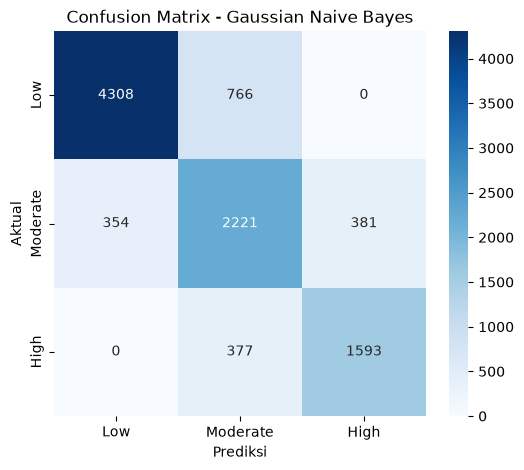

In [3]:
# 1. Model k-NN Terbaik
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(sub_train, sub_y)
y_pred_knn = best_knn.predict(sub_test)

# 2. Model Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)
y_pred_gnb = gnb.predict(X_test_scaled)

print("--- Evaluasi Gaussian Naive Bayes ---")
print(f"Akurasi: {accuracy_score(y_test, y_pred_gnb) * 100:.2f}%")
print(classification_report(y_test, y_pred_gnb))

# Visualisasi Confusion Matrix Gaussian Naive Bayes
labels_order = ['Low', 'Moderate', 'High']
cm = confusion_matrix(y_test, y_pred_gnb, labels=labels_order)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_order, yticklabels=labels_order)
plt.title('Confusion Matrix - Gaussian Naive Bayes', fontsize=12)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

### Kesimpulan JS09:
1. Algoritma Gaussian Naive Bayes sangat cepat dieksekusi pada data tabular skala besar dan menghasilkan performa klasifikasi yang seimbang antar-kelas.
2. Pada k-NN, nilai $k=7$ memberikan akurasi yang stabil dengan batas keputusan (*decision boundary*) yang halus tanpa *overfitting*.